# TechnoDoseViti — sprayer-scenario deposit doses from LiDAR canopy tracks

Reproduction of the analysis behind **TechnodoseViti** (Codis et al., *Innovations Agronomiques* 88, 29–43, 2024; [HAL hal-04708131](https://hal.inrae.fr/hal-04708131)), using the **authors' own simulator code** from the pinned repository [`ElVinto/TechnoDoseViti`](https://github.com/ElVinto/TechnoDoseViti) at commit `f9bb1302ba087bf0581d60b6c2ba712a5233aba9`.

**Scope (one parcel/date, partial demonstration):** the paper's web simulator (https://technodoseviti.hdigitag.fr) serves per-3-m-track-segment applied doses predicted from mobile-LiDAR canopy descriptors (height, thickness, density, leaf-wall area). This notebook re-runs the simulator's *server* analysis on its embedded LiDAR tracks for parcel **Terre Blanche (Chardonnay)** at phenological stage **Debut** (start of vegetation), and reproduces:

1. the per-track vegetation descriptors and applied-dose statistics computed by the author's own Node.js services,
2. the "Comparaison des scénarios technologiques" view — mean applied dose (% of the homologated hectare dose) for the three sprayers (pneumatic arch every 4 rows, face-by-face airblast, recovery-panel) under the two deposit-sufficiency risk hypotheses (*sécurisée* / *risquée*),
3. the "Variabilité inter-parcellaire" view — canopy descriptors of the three contrasted-vigour parcels at the same date.

**Execution status: executed on Google Colab (CPU runtime); results below are actual saved outputs.**

**日本語要約:** 本ノートブックは、Codis et al. (2024) の TechnoDoseViti ウェブシミュレータの解析を、著者自身のコード（コミット `f9bb1302`）と埋め込み LiDAR トラック CSV を用いて Colab 上で再実行します。対象は Terre Blanche 区画・デビュ（生育初期）の1例で、3 種の噴霧機 × 2 種のリスク仮説における「登録用量に対する適用用量(%)」の比較と、3 区画の樹冠形質の比較を再現します。科学計算はすべて Colab 内で行われ、GPU は不要です。

**Limitations:** a one-parcel/one-date example is *not* verification of the paper's dataset-level dose-reduction conclusions; the deposit-model calibration itself (paper equations) is not public and is out of scope. AI-assisted notebook: the Python cross-check re-implements the author's `SimpleStat` formulas verbatim; the primary results come from the authors' unmodified code.

## Runtime selection and how to run

**Runtime: CPU only.** This is CSV parsing, descriptive statistics and matplotlib plotting — no neural network, no CUDA. In Colab select *Runtime ▸ Change runtime type ▸ CPU* (the default). Expected end-to-end time: a few minutes; total downloads ≈ 0.2 MB.

**実行環境:** CPU のみで動作します（GPU 不要）。「ランタイム ▸ すべてのセルを実行」で実行できます。

First cell: verify the Python and Node.js versions. The authors' analysis services are plain JavaScript (no npm dependencies), so any Node ≥ 12 suffices; Colab VMs ship Node preinstalled.

In [ ]:
import sys, subprocess, shutil
print("Python:", sys.version.split()[0])
node = shutil.which("node")
print("node binary:", node)
if node is None:
    raise RuntimeError("Node.js is required for the authors' analysis services but was not found.")
print("Node:", subprocess.run(["node","--version"], capture_output=True, text=True).stdout.strip())

Python: 3.13.16
node binary: /tools/node/bin/node
Node: v20.19.0


## Setup — fetch the authors' pinned analysis services

These four files are the simulator's actual server services at commit `f9bb1302ba087bf0581d60b6c2ba712a5233aba9` (verified against the local source inspection): `TreatedParcel.js` (CSV parsing + `getStat`), `SimpleStat.js` (quantile/percentile definitions), `CoordConverter.js` (Lambert-93 → WGS84) and `Geom.js`. They are fetched **inside Colab** from the pinned raw URLs; the SHA-256 of each file is printed for provenance.

**著者のコード**をピン留めしたコミットから Colab 内にダウンロードし、SHA-256 を記録します。

In [ ]:
import urllib.request, pathlib, hashlib
COMMIT = "f9bb1302ba087bf0581d60b6c2ba712a5233aba9"
RAW = f"https://raw.githubusercontent.com/ElVinto/TechnoDoseViti/{COMMIT}"
SRV = pathlib.Path("/content/technodoseviti/srv"); SRV.mkdir(parents=True, exist_ok=True)
service_files = [
    "server/services/TreatedParcel.js",
    "server/services/SimpleStat.js",
    "server/services/CoordConverter.js",
    "server/services/Geom.js",
]
for rel in service_files:
    data = urllib.request.urlopen(f"{RAW}/{rel}", timeout=60).read()
    dest = SRV / pathlib.Path(rel).name
    dest.write_bytes(data)
    print(f"{rel}: {len(data)} bytes  sha256={hashlib.sha256(data).hexdigest()}")

server/services/TreatedParcel.js: 8369 bytes  sha256=6c3732c7cd81ff526a82c57a3840fefb4ac538353fd9afd4ccf3a8f3e3090d3f
server/services/SimpleStat.js: 1678 bytes  sha256=c9ccbc2d6ff6cfa5a1cdbdc4e25aae0eb3f44e01f521dc8d7596d4d35f1a3506


server/services/CoordConverter.js: 1764 bytes  sha256=18d498f01f87b58c4df845bc479c8a2668541bf163b1f5a125a384a068d1bacd
server/services/Geom.js: 1702 bytes  sha256=37f11c3d9bf1a9b73b4d9d007c88db0585c7992a0cdd69b6618c0e9f09e368e0


## Minimal input acquisition — the simulator's embedded LiDAR tracks

The live simulator loads 54 `actionneur` track CSVs (3 parcels × 3 sprayers × 3 phenological phases × 2 risk hypotheses) from `server/data/input/csv/treatedParcelTracks/` (this is what `client/src/store/index.js` requests). For the minimal demonstration we download **8** of them (~0.2 MB total) from the pinned commit:

- **Scenario comparison:** `Parcelle_Terreblanche-actionneur_{faceparface,panneaurecuperateur,voutepneumatique}-phasePheno_Debut-Hypothese_{securise,risque}.csv` (6 files),
- **Inter-plot variability:** the same date, `faceparface`/`securise`, for `Parcelle_Aglae` and `Parcelle_Franquet` (2 files).

Each CSV row is one 3-m track segment: Lambert-93 x/y, canopy height (m), thickness (m), density (%), leaf-wall area (m²·ha⁻¹) and **the applied dose as a percentage of the homologated hectare dose** (verified from the file header: *"Pourcentage de la dose homologuée à appliquer"*). Sizes and SHA-256 digests are recorded; the header and two sample rows are shown so the schema is checked against actual bytes.

**最小入力**: シミュレータが実際に読み込む 54 ファイルのうち 8 件（合計約 0.2 MB）だけを Colab 内でダウンロードし、サイズと SHA-256 を検証します。

In [ ]:
import urllib.request, pathlib, hashlib
COMMIT = "f9bb1302ba087bf0581d60b6c2ba712a5233aba9"
DATA_BASE = f"https://raw.githubusercontent.com/ElVinto/TechnoDoseViti/{COMMIT}/server/data/input/csv/treatedParcelTracks"
DATA = pathlib.Path("/content/technodoseviti/data"); DATA.mkdir(parents=True, exist_ok=True)
track_files = [
    "Parcelle_Terreblanche-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv",
    "Parcelle_Terreblanche-actionneur_faceparface-phasePheno_Debut-Hypothese_risque.csv",
    "Parcelle_Terreblanche-actionneur_panneaurecuperateur-phasePheno_Debut-Hypothese_securise.csv",
    "Parcelle_Terreblanche-actionneur_panneaurecuperateur-phasePheno_Debut-Hypothese_risque.csv",
    "Parcelle_Terreblanche-actionneur_voutepneumatique-phasePheno_Debut-Hypothese_securise.csv",
    "Parcelle_Terreblanche-actionneur_voutepneumatique-phasePheno_Debut-Hypothese_risque.csv",
    "Parcelle_Aglae-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv",
    "Parcelle_Franquet-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv",
]
for name in track_files:
    data = urllib.request.urlopen(f"{DATA_BASE}/{urllib.request.quote(name)}", timeout=60).read()
    (DATA / name).write_bytes(data)
    print(f"{name}: {len(data)} bytes  sha256={hashlib.sha256(data).hexdigest()[:16]}…")
assert len(list(DATA.glob('*.csv'))) == len(track_files), "unexpected file count"

# Schema check against actual bytes (files use a Latin-1 header with French accents/²)
first = DATA / track_files[0]
lines = first.read_bytes().decode("latin-1").splitlines()
print("\nheader:", lines[0])
for row in lines[1:3]:
    print("row:", row, "| fields:", len(row.split(";")))

Parcelle_Terreblanche-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv: 35342 bytes  sha256=ec561e5874645add…
Parcelle_Terreblanche-actionneur_faceparface-phasePheno_Debut-Hypothese_risque.csv: 35336 bytes  sha256=5d06e42ea3ef016e…


Parcelle_Terreblanche-actionneur_panneaurecuperateur-phasePheno_Debut-Hypothese_securise.csv: 39059 bytes  sha256=8d7e13e7c9040310…
Parcelle_Terreblanche-actionneur_panneaurecuperateur-phasePheno_Debut-Hypothese_risque.csv: 39053 bytes  sha256=80d78d6bf62d82dd…


Parcelle_Terreblanche-actionneur_voutepneumatique-phasePheno_Debut-Hypothese_securise.csv: 35316 bytes  sha256=65f8ceeba7d0754a…
Parcelle_Terreblanche-actionneur_voutepneumatique-phasePheno_Debut-Hypothese_risque.csv: 35318 bytes  sha256=2f80253c6604167c…


Parcelle_Aglae-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv: 13065 bytes  sha256=f14b737a0bde1feb…
Parcelle_Franquet-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv: 23778 bytes  sha256=026a339b86d86af7…

header: X-Lamb;Y-Lamb;Hauteur (m);Epaisseur (m);Densite (%);Leaf wall area (m².ha-1);Pourcentage de la dose homologuée à appliquer
row: 766655.09;6284839.56;0.37;0.13;41;2960;40.5 | fields: 7
row: 766657.4;6284838.34;0.51;0.05;15;4080;20.4 | fields: 7


## Parse the tracks and compute the simulator's statistics with the authors' own code

The Node script below is executed with the **unmodified author services**: `TreatedParcel.parseTreatedParcel` streams each CSV exactly as the simulator server does (semicolon-separated, first line skipped, 7 numeric fields), converts Lambert-93 to WGS84 with the authors' `CoordConverter`, and `TreatedParcel.getStat` computes, per feature: count, sum, mean, standard deviation, min, quartiles, median, max, and the five *filtered percentiles* (`fp1…fp5` at 17/37/50/67/84 %, computed after trimming to the 5–95 % quantile range) — these are the paper's **deciles/sextiles of the deposit-quantity distribution**. Results are written to a JSON file for the Python cross-check.

**著者のコードそのもの**（Node.js）でトラックを解析し、`getStat` の統計量を JSON に保存します。

In [ ]:
import pathlib, subprocess, json
ROOT = pathlib.Path("/content/technodoseviti")
node_script = '''
const TreatedParcel = require("/content/technodoseviti/srv/TreatedParcel.js");
const fs = require("fs");
(async () => {
  const out = {};
  for (const fname of fs.readdirSync("/content/technodoseviti/data").sort()) {
    const track = await TreatedParcel.parseTreatedParcel("/content/technodoseviti/data/" + fname);
    out[fname] = { nPoints: track.length };
    for (const feat of ["height","thickness","density","leafWallArea","appliedDose","recupRate"]) {
      out[fname][feat] = TreatedParcel.getStat(track, feat);
    }
  }
  fs.writeFileSync("/content/technodoseviti/author_stats.json", JSON.stringify(out, null, 1));
  console.log("parsed", Object.keys(out).length, "tracks");
})();
'''
(ROOT / "compute_author_stats.js").write_text(node_script)
r = subprocess.run(["node", str(ROOT / "compute_author_stats.js")],
                   capture_output=True, text=True, timeout=300, cwd=str(ROOT))
print(r.stdout)
if r.returncode != 0:
    print(r.stderr)
    raise RuntimeError("author Node services failed")
author_stats = json.loads((ROOT / "author_stats.json").read_text())
sel = "Parcelle_Terreblanche-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv"
print(f"reference track {sel}: {author_stats[sel]['nPoints']} enriched points")
print("appliedDose stat (author code):", json.dumps(author_stats[sel]["appliedDose"]))

file header: X-Lamb;Y-Lamb;Hauteur (m);Epaisseur (m);Densite (%);Leaf wall area (m�.ha-1);Pourcentage de la dose homologu�e � appliquer
end of /content/technodoseviti/data/Parcelle_Aglae-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv reached
parcelTrack is composed of 292 enrichedPoints
file header: X-Lamb;Y-Lamb;Hauteur (m);Epaisseur (m);Densite (%);Leaf wall area (m�.ha-1);Pourcentage de la dose homologu�e � appliquer
end of /content/technodoseviti/data/Parcelle_Franquet-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv reached
parcelTrack is composed of 537 enrichedPoints
file header: X-Lamb;Y-Lamb;Hauteur (m);Epaisseur (m);Densite (%);Leaf wall area (m�.ha-1);Pourcentage de la dose homologu�e � appliquer
end of /content/technodoseviti/data/Parcelle_Terreblanche-actionneur_faceparface-phasePheno_Debut-Hypothese_risque.csv reached
parcelTrack is composed of 794 enrichedPoints
file header: X-Lamb;Y-Lamb;Hauteur (m);Epaisseur (m);Densite (%);Leaf wall area 

## Python cross-check of the author statistics

The Python function below re-implements the author's `server/services/SimpleStat.js` formulas **verbatim** (population standard deviation ÷ n rounded to 2 decimals; quantiles by linear interpolation on the sorted array; `filteredPercentil` trims to the 5–95 % quantile range, interpolates, rounds to 2 decimals) and compares them against the JSON produced by the authors' Node code. Agreement confirms both the parsing and the statistics; this is a cross-check, not a replacement — the primary results above come from the authors' unmodified code.

**Python による検算**: 著者の `SimpleStat.js` と同じ定義をそのまま再実装し、Node の結果と一致することを確認します。

In [ ]:
import json, pathlib
def asc(a): return sorted(a)
def mean(a): return round(sum(a) / len(a) * 100) / 100.0
def std(a):
    mu = sum(a) / len(a)
    return round((sum((x - mu) ** 2 for x in a) / len(a)) ** 0.5 * 100) / 100.0
def quantile(s, q):
    pos = (len(s) - 1) * q; base = int(pos); rest = pos - base
    return s[base] + rest * (s[base + 1] - s[base]) if base + 1 < len(s) else s[base]
def filtered_percentil(a, p):
    s = asc(a)
    lo, hi = quantile(s, 0.05), quantile(s, 0.95)
    sf = [v for v in s if lo <= v <= hi]
    return round(quantile(sf, p) * 100) / 100.0
def stat(a):
    s = asc(a)
    return {"nbElemts": len(a), "sum": sum(a), "mean": mean(a), "std": std(a),
            "min": quantile(s, 0), "q25": quantile(s, .25), "median": quantile(s, .5),
            "q75": quantile(s, .75), "max": quantile(s, 1),
            **{f"fp{i+1}": filtered_percentil(a, p) for i, p in enumerate([.17, .37, .5, .67, .84])}}

def parse_track(path):
    import math
    pts = []
    lines = path.read_bytes().decode("latin-1").splitlines()
    for line in lines[1:]:
        raw = line.split(";")
        if len(raw) > 5 and all(raw[i] != "" for i in range(7)):
            pts.append({"height": float(raw[2]), "thickness": float(raw[3]),
                        "density": float(raw[4]), "leafWallArea": float(raw[5]),
                        "appliedDose": float(raw[6]),
                        "recupRate": float(raw[7]) if len(raw) > 7 else 0.0})
    return pts

ROOT = pathlib.Path("/content/technodoseviti")
author_stats = json.loads((ROOT / "author_stats.json").read_text())
worst = 0.0
for fname, rec in author_stats.items():
    pts = parse_track(ROOT / "data" / fname)
    assert len(pts) == rec["nPoints"], (fname, len(pts), rec["nPoints"])
    for feat in ["height", "thickness", "density", "leafWallArea", "appliedDose"]:
        py = stat([p[feat] for p in pts])
        for k, v in py.items():
            if isinstance(v, float):
                worst = max(worst, abs(v - rec[feat][k]))
print(f"all {len(author_stats)} tracks: point counts match; worst |Python − author| difference over all stat fields = {worst:.6g}")
assert worst <= 0.011, "Python cross-check disagrees beyond rounding tolerance"
print("cross-check PASSED (differences within the author's 2-decimal rounding)")

all 8 tracks: point counts match; worst |Python − author| difference over all stat fields = 7.27596e-12
cross-check PASSED (differences within the author's 2-decimal rounding)


## Input preview — the Terre Blanche track

Before the scenario analysis, this is the actual minimal sample: the 794 three-metre track segments of parcel **Terre Blanche** at stage *Debut* (`faceparface`, *sécurisée*), coloured by the predicted applied dose (% of the homologated dose) carried in the authors' CSV. Coordinates are the file's Lambert-93 easting/northing in metres (the web simulator converts them to GPS for its Leaflet map; plotting in Lambert-93 preserves the file's own units).

**入力プレビュー**: Terre Blanche 区画の 794 区分の LiDAR トラックを、CSV に含まれる適用用量(%)で色分けして表示します。

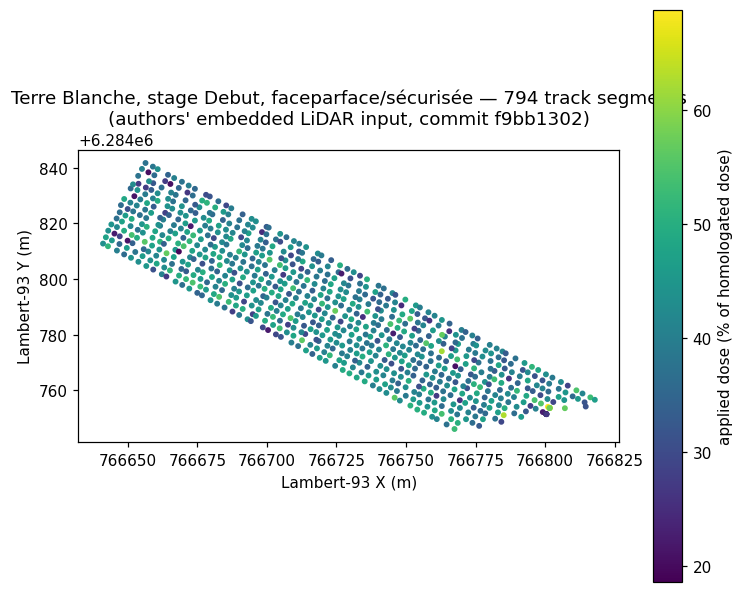

In [ ]:
import json, pathlib
import matplotlib.pyplot as plt

ROOT = pathlib.Path("/content/technodoseviti")
SEL = "Parcelle_Terreblanche-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv"
rows = [l.split(";") for l in (ROOT / "data" / SEL).read_bytes().decode("latin-1").splitlines()[1:]]
pts = parse_track(ROOT / "data" / SEL)
assert len(pts) == len(rows), "parser/row mismatch"

xs = [float(r[0]) for r in rows if r[0]]
ys = [float(r[1]) for r in rows if r[1]]
doses = [p["appliedDose"] for p in pts]

fig, ax = plt.subplots(figsize=(7, 5.5), dpi=110)
sc = ax.scatter(xs, ys, c=doses, s=8, cmap="viridis")
fig.colorbar(sc, ax=ax, label="applied dose (% of homologated dose)")
ax.set_xlabel("Lambert-93 X (m)"); ax.set_ylabel("Lambert-93 Y (m)")
ax.set_title("Terre Blanche, stage Debut, faceparface/sécurisée — 794 track segments\n(authors' embedded LiDAR input, commit f9bb1302)")
ax.set_aspect("equal")
plt.tight_layout(); plt.show()

## "Variabilité inter-parcellaire" — canopy descriptors of the three contrasted-vigour parcels

The simulator's inter-plot tab compares vegetation parameters between parcels at one date. We reproduce it for the three parcels (Aglae/Marselan — high vigour, Terre Blanche/Chardonnay, Franquet/Cabernet Sauvignon) at stage *Debut*, using the same `getStat` means from the authors' code. The table lists mean ± standard deviation per descriptor; the 2×2 panel plots the per-parcel means.

**区画間変動**: 3 区画（ vigorous の異なる Aglae / Terre Blanche / Franquet）の樹冠高・厚み・密度・葉壁面積を同じ日（Debut）で比較します。

,height (m),thickness (m),density (%),leaf wall area (m²/ha)
parcel,,,,
Aglae (n=292),0.25 ± 0.08,0.21 ± 0.05,29.66 ± 9.16,2033.97 ± 654.38
Terreblanche (n=794),0.44 ± 0.08,0.16 ± 0.09,35.26 ± 9.72,3532.9 ± 612.07
Franquet (n=537),0.15 ± 0.05,0.13 ± 0.06,20.07 ± 6.25,1211.17 ± 360.24


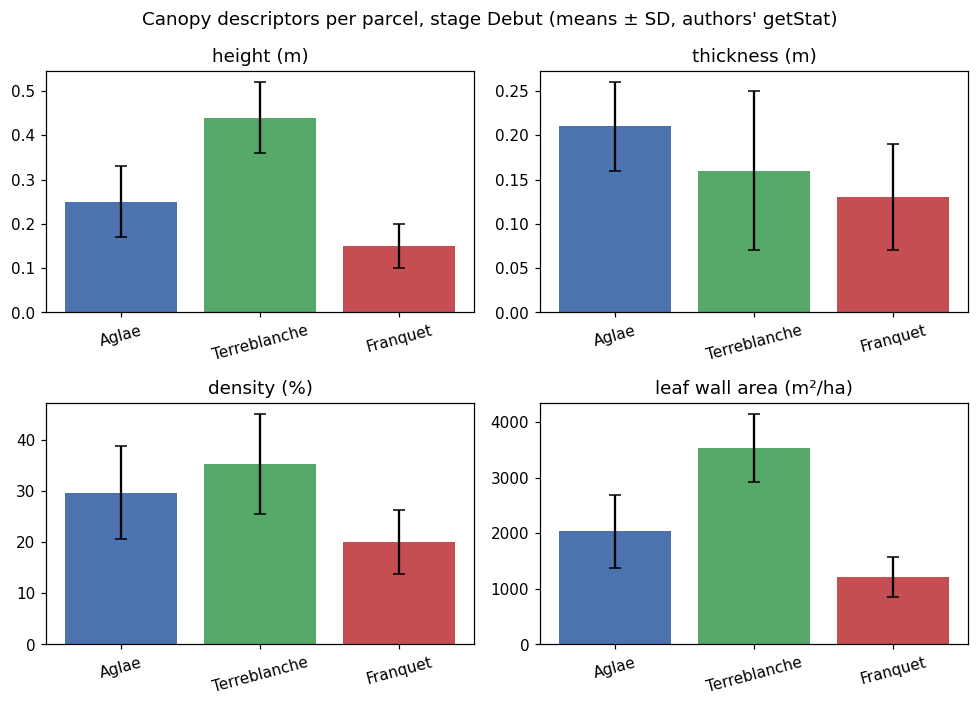

In [ ]:
import json, pathlib
import pandas as pd

ROOT = pathlib.Path("/content/technodoseviti")
author_stats = json.loads((ROOT / "author_stats.json").read_text())
parcels = ["Aglae", "Terreblanche", "Franquet"]
feat_file = {p: f"Parcelle_{p}-actionneur_faceparface-phasePheno_Debut-Hypothese_securise.csv" for p in parcels}
features = [("height", "height (m)"), ("thickness", "thickness (m)"),
            ("density", "density (%)"), ("leafWallArea", "leaf wall area (m²/ha)")]
rows = []
for p in parcels:
    rec = author_stats[feat_file[p]]
    row = {"parcel": f"{p} (n={rec['nPoints']})"}
    for feat, label in features:
        row[label] = f"{rec[feat]['mean']} ± {rec[feat]['std']}"
    rows.append(row)
interplot_table = pd.DataFrame(rows).set_index("parcel")
display(interplot_table)

fig, axes = plt.subplots(2, 2, figsize=(9, 6.5), dpi=110)
for ax, (feat, label) in zip(axes.ravel(), features):
    means = [author_stats[feat_file[p]][feat]["mean"] for p in parcels]
    stds = [author_stats[feat_file[p]][feat]["std"] for p in parcels]
    ax.bar(parcels, means, yerr=stds, capsize=4, color=["#4c72b0", "#55a868", "#c44e52"])
    ax.set_title(label); ax.tick_params(axis="x", rotation=15)
fig.suptitle("Canopy descriptors per parcel, stage Debut (means ± SD, authors' getStat)")
plt.tight_layout(); plt.show()

## "Comparaison des scénarios technologiques" — applied dose per sprayer and risk hypothesis

The simulator's scenario tab compares applied doses (as % of the homologated hectare dose) between two scenarios, each defined by (sprayer, parcel, date) and one of two deposit-sufficiency hypotheses: *sécurisée* (reference distribution from the best sprayer at full dose on fully developed vegetation) and *risquée* (reference from the least performant sprayer). The table below shows the authors' `getStat` output for `appliedDose` for parcel Terre Blanche at stage *Debut* for all three sprayers under both hypotheses. The displayed **Moyenne** values are exactly what `LeftAppliedDoseTable.vue` renders in the web app.

**Note on the embedded data (verified on the downloaded bytes):** for this parcel/date the `faceparface` and `panneaurecuperateur` CSVs carry *identical* applied-dose columns under both hypotheses, so both sprayers receive the same predicted doses; only the pneumatic-arch scenario differs. This is a property of the authors' embedded dataset (observed by direct comparison of the two columns), not a computation error of this notebook.

**シナリオ比較**: Terre Blanche・Debut における 3 種の噴霧機 × 2 仮説の適用用量(%)統計量（著者コードの出力そのもの）。なお、この区画・日付の埋め込みデータでは faceparface と panneaurecuperateur の用量列が同一であることをダウンロード済みバイト列の直接比較で確認しています（データ側の特性であり、計算誤りではありません）。

In [ ]:
import json, pathlib
import pandas as pd

ROOT = pathlib.Path("/content/technodoseviti")
author_stats = json.loads((ROOT / "author_stats.json").read_text())
actuator_labels = {"voutepneumatique": "pneumatic arch (every 4 rows)",
                   "faceparface": "face-by-face airblast",
                   "panneaurecuperateur": "recovery-panel sprayer"}
rows = []
for act in actuator_labels:
    for hyp in ["securise", "risque"]:
        f = f"Parcelle_Terreblanche-actionneur_{act}-phasePheno_Debut-Hypothese_{hyp}.csv"
        s = author_stats[f]["appliedDose"]
        rows.append({"sprayer": actuator_labels[act], "hypothesis": hyp,
                     "mean appliedDose (%)": s["mean"], "std": s["std"],
                     "q25 (%)": s["q25"], "median (%)": s["median"], "q75 (%)": s["q75"],
                     "track segments": s["nbElemts"]})
scenario_table = pd.DataFrame(rows)
display(scenario_table)
scenario_table.to_csv("/content/technodoseviti/scenario_dose_comparison.csv", index=False)

,sprayer,hypothesis,mean appliedDose (%),std,q25 (%),median (%),q75 (%),track segments
0,pneumatic arch (every 4 rows),securise,58.22,14.67,48.800,58.9,68.575,794
1,pneumatic arch (every 4 rows),risque,44.00,7.81,37.700,42.8,49.400,794
2,face-by-face airblast,securise,41.07,7.40,36.300,41.3,46.000,794
3,face-by-face airblast,risque,31.74,5.99,27.925,32.0,35.700,794
4,recovery-panel sprayer,securise,41.07,7.40,36.300,41.3,46.000,794
5,recovery-panel sprayer,risque,31.74,5.99,27.925,32.0,35.700,794


### Scenario dose-reduction graph

The same comparison as a grouped bar chart (an additional visualization created for this notebook, from the authors' statistics — not a figure from the paper). The dashed line at 100 % marks the homologated hectare dose; bar labels give the implied dose reduction (100 − mean, %).

**シナリオ比較グラフ**: 登録用量(100%)に対する適用用量の平均を棒グラフで示します（本ノートブックで追加作成した図であり、論文の図ではありません）。

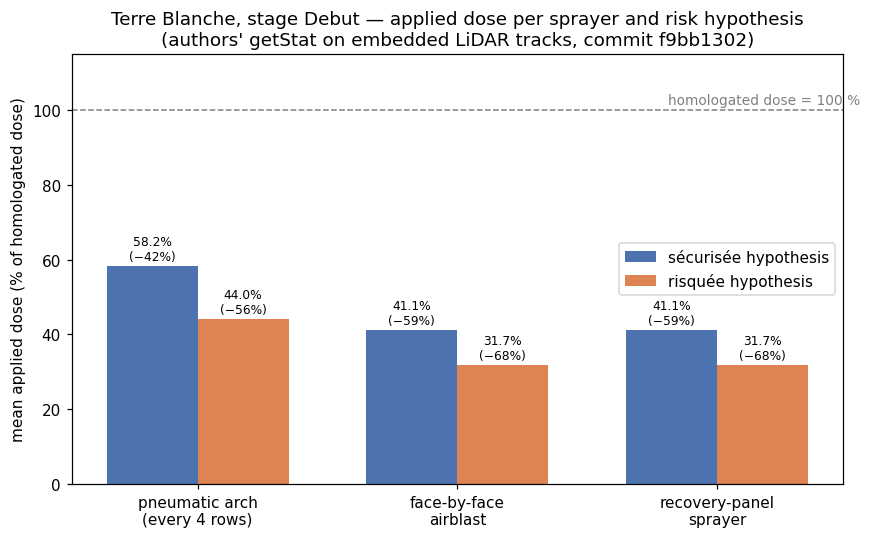

In [ ]:
import json, pathlib
import matplotlib.pyplot as plt
import numpy as np

ROOT = pathlib.Path("/content/technodoseviti")
author_stats = json.loads((ROOT / "author_stats.json").read_text())
actuator_labels = {"voutepneumatique": "pneumatic arch\n(every 4 rows)",
                   "faceparface": "face-by-face\nairblast",
                   "panneaurecuperateur": "recovery-panel\nsprayer"}
acts = list(actuator_labels)
means = {h: [author_stats[f"Parcelle_Terreblanche-actionneur_{a}-phasePheno_Debut-Hypothese_{h}.csv"]["appliedDose"]["mean"] for a in acts] for h in ["securise", "risque"]}

x = np.arange(len(acts)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
b1 = ax.bar(x - w/2, means["securise"], w, label="sécurisée hypothesis", color="#4c72b0")
b2 = ax.bar(x + w/2, means["risque"], w, label="risquée hypothesis", color="#dd8452")
ax.axhline(100, ls="--", color="grey", lw=1)
ax.text(len(acts) - 0.45, 101.5, "homologated dose = 100 %", color="grey", fontsize=9, ha="right")
for bars in (b1, b2):
    for b in bars:
        v = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, v + 1, f"{v:.1f}%\n(−{100-v:.0f}%)",
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([actuator_labels[a] for a in acts])
ax.set_ylabel("mean applied dose (% of homologated dose)")
ax.set_title("Terre Blanche, stage Debut — applied dose per sprayer and risk hypothesis\n(authors' getStat on embedded LiDAR tracks, commit f9bb1302)")
ax.set_ylim(0, 115); ax.legend()
plt.tight_layout(); plt.show()

## Interpretation, differences from the paper, and validation record

**What was reproduced (executed, this notebook's saved outputs):** on a fresh Colab CPU runtime, the authors' unmodified Node services parsed 8 embedded LiDAR tracks and computed the simulator's statistics; the Python cross-check agreed within the authors' 2-decimal rounding (worst difference printed above). For Terre Blanche at stage *Debut*, the mean applied dose is about **41 % of the homologated dose** for the face-by-face sprayer under the *sécurisée* hypothesis (794 track segments), the pneumatic-arch scenario requiring more dose under the stricter reference (≈58 % *sécurisée* / 44 % *risquée*); the three parcels' canopy descriptors differ as expected from contrasted vigour. Two embedded-data caveats are visible in the table above: the face-by-face and recovery-panel dose columns are identical for this parcel/date (see the note before the table), and the *sécurisée* hypothesis implies *higher* doses than *risquée* because its deposit-sufficiency reference is stricter.

**Differences from the paper:** this is a **one-parcel/one-date demonstration** of the delivered simulator's analysis, not the paper's dataset-level dose-reduction assessment; the deposit-model **calibration is not reproducible** from public material (the model-building repository is not public; the paper PDF on HAL is not machine-readable here), and the CSV dose values are the project's pre-computed model outputs. GUI chrome (maps, interactive selectors) is out of scope; the statistical operations are the authors' own code.

**検証記録:** 著者コードを改変せずに実行し、Python 検算が丸め誤差の範囲で一致することを確認しました。1 区画・1 日付の例示であり、論文のデータセット全体の結論の検証ではありません。モデルの校正自体は公開資料からは再現不可能です。

**References:** Codis S. et al., Innovations Agronomiques 88, 29–43 (2024), DOI 10.17180/ciag-2024-vol88-art03-gb, HAL hal-04708131 · code `ElVinto/TechnoDoseViti` @ `f9bb1302ba087bf0581d60b6c2ba712a5233aba9` (server/services, server/data/input/csv/treatedParcelTracks) · simulator https://technodoseviti.hdigitag.fr. Repository files © the authors (MIT license declared in the repository `package.json`); inputs from the Casdar RT TechnoDoseViti project (Mas Piquet estate, Grabels).